# 04 – Indicateur d'artificialisation

Dans le notebook 03, la comparaison des **surfaces totales** de bâti entre années s'est révélée fragile : de petites différences entre les images suffisent à faire varier le total de plusieurs km², même dans des quartiers qui n'ont pas changé.

Je mesure donc plutôt des **flux**, pixel par pixel, entre deux dates :
- **gains** : pixels non bâtis à la première date et bâtis à la seconde (artificialisation) ;
- **pertes** : pixels bâtis puis non bâtis. En réalité ce flux est quasi nul (on ne « désartificialise » presque jamais), donc les pertes détectées donnent un **ordre de grandeur du bruit** de la méthode.

Trois filtres contre les faux changements :
1. exclusion des pixels sans donnée (nuages masqués) **et d'une bande de 30 m autour**, où le modèle est perturbé par le bord du masque ;
2. **seuil de confiance** : probabilité max du modèle ≥ 0,7 aux deux dates ;
3. **surface minimale** : taches de changement d'au moins 0,5 ha (un chantier fait rarement moins), ce qui enlève le bruit pixel par pixel.

## 1. Chargement des cartes

In [11]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import rasterio
import cv2

DATA_DIR = Path("data_saclay")
RES_DIR = Path("resultats")
CARTES_DIR = RES_DIR / "cartes"

NOMS_CLASSES = ["Bâti", "Forêt / arbres", "Cultures", "Prairies / autre", "Eau"]
BATI = 0
NODATA = 255
HA_PIXEL = 10 * 10 / 1e4      # 1 pixel = 0,01 ha

SEUIL_CONFIANCE = 0.7         # proba max minimale aux deux dates
SURFACE_MIN_HA = 0.5          # taille minimale d'une tache de changement
MARGE_NODATA = 3              # pixels exclus autour des zones sans donnée

cartes, confiance = {}, {}
for annee in ["2017", "2021", "2025"]:
    with rasterio.open(CARTES_DIR / f"occupation_{annee}.tif") as src:
        cartes[annee] = src.read(1)
        profil = src.profile
    with rasterio.open(CARTES_DIR / f"confiance_{annee}.tif") as src:
        confiance[annee] = src.read(1)

H, W = cartes["2017"].shape
print(f"Cartes : {W} x {H} pixels ({W * H * HA_PIXEL / 100:.0f} km²)")

Cartes : 4012 x 3711 pixels (1489 km²)


## 2. Calcul des flux entre deux dates

In [12]:
def masque_valide(a, b):
    nodata = (cartes[a] == NODATA) | (cartes[b] == NODATA)
    noyau = np.ones((2 * MARGE_NODATA + 1, 2 * MARGE_NODATA + 1), np.uint8)
    nodata = cv2.dilate(nodata.astype(np.uint8), noyau).astype(bool)
    return ~nodata


def filtrer_surface(masque, surface_min_ha):
    # j'enlève les taches (8-connexité) plus petites que surface_min_ha
    n, etiquettes, stats, _ = cv2.connectedComponentsWithStats(masque.astype(np.uint8), connectivity=8)
    garder = stats[:, cv2.CC_STAT_AREA] * HA_PIXEL >= surface_min_ha
    garder[0] = False  # fond
    return garder[etiquettes]


def flux(a, b, seuil=SEUIL_CONFIANCE, surface_min=SURFACE_MIN_HA):
    valide = masque_valide(a, b)
    sur = (confiance[a] >= seuil) & (confiance[b] >= seuil)
    bati_a, bati_b = cartes[a] == BATI, cartes[b] == BATI

    gains_brut = valide & ~bati_a & bati_b
    pertes_brut = valide & bati_a & ~bati_b
    gains = filtrer_surface(gains_brut & sur, surface_min)
    pertes = filtrer_surface(pertes_brut & sur, surface_min)
    return {
        "valide": valide, "gains_brut": gains_brut, "pertes_brut": pertes_brut,
        "gains": gains, "pertes": pertes,
        "bati_initial_ha": float((bati_a & valide).sum() * HA_PIXEL),
    }


def resume(a, b, f):
    g, p = f["gains"].sum() * HA_PIXEL, f["pertes"].sum() * HA_PIXEL
    gb, pb = f["gains_brut"].sum() * HA_PIXEL, f["pertes_brut"].sum() * HA_PIXEL
    duree = int(b) - int(a)
    return {
        "periode": f"{a}-{b}", "duree_ans": duree,
        "gains_bruts_ha": float(gb), "pertes_brutes_ha": float(pb),
        "gains_ha": float(g), "pertes_ha": float(p), "net_ha": float(g - p),
        "net_ha_par_an": float((g - p) / duree),
        "taux_artificialisation": float((g - p) / f["bati_initial_ha"]),
        "part_zone_valide": float(f["valide"].mean()),
    }


periodes = [("2017", "2021"), ("2021", "2025"), ("2017", "2025")]
resultats, flux_calcules = [], {}
for a, b in periodes:
    flux_calcules[(a, b)] = flux(a, b)
    resultats.append(resume(a, b, flux_calcules[(a, b)]))

print(f"{'Période':10s} {'Gains bruts':>12s} {'Pertes brutes':>14s} {'Gains':>9s} {'Pertes':>9s} {'Net':>9s} {'Net/an':>9s} {'Taux':>7s}")
for r in resultats:
    print(f"{r['periode']:10s} {r['gains_bruts_ha']:10.0f} ha {r['pertes_brutes_ha']:11.0f} ha "
          f"{r['gains_ha']:6.0f} ha {r['pertes_ha']:6.0f} ha {r['net_ha']:6.0f} ha {r['net_ha_par_an']:6.0f} ha "
          f"{r['taux_artificialisation']:7.1%}")

Période     Gains bruts  Pertes brutes     Gains    Pertes       Net    Net/an    Taux
2017-2021        3921 ha        4462 ha    190 ha     29 ha    161 ha     40 ha    0.4%
2021-2025        7217 ha        3479 ha    159 ha     82 ha     76 ha     19 ha    0.2%
2017-2025        5604 ha        2671 ha    335 ha     60 ha    275 ha     34 ha    0.6%


Colonnes « brutes » : simple comparaison des deux cartes. Les autres : après filtrage (confiance + surface minimale).

## 3. Origine des surfaces artificialisées (2017 → 2025)

In [13]:
f = flux_calcules[("2017", "2025")]
origine = cartes["2017"][f["gains"]]
print("Classe en 2017 des surfaces devenues bâties en 2025 :")
origine_ha = {}
for c, nom in enumerate(NOMS_CLASSES):
    if c == BATI:
        continue
    ha = (origine == c).sum() * HA_PIXEL
    origine_ha[nom] = float(ha)
    print(f"  {nom:18s} {ha:8.0f} ha  ({ha / max(f['gains'].sum() * HA_PIXEL, 1e-9):5.1%})")

# matrice de transition complète en ha (seulement les pixels valides et sûrs aux deux dates)
sur = f["valide"] & (confiance["2017"] >= SEUIL_CONFIANCE) & (confiance["2025"] >= SEUIL_CONFIANCE)
mat = np.zeros((5, 5))
for i in range(5):
    for j in range(5):
        mat[i, j] = ((cartes["2017"] == i) & (cartes["2025"] == j) & sur).sum() * HA_PIXEL
print("\nMatrice de transition 2017 (lignes) -> 2025 (colonnes), en ha :")
print(f"{'':18s}" + "".join(f"{n[:10]:>12s}" for n in NOMS_CLASSES))
for i, nom in enumerate(NOMS_CLASSES):
    print(f"{nom:18s}" + "".join(f"{v:12.0f}" for v in mat[i]))

Classe en 2017 des surfaces devenues bâties en 2025 :
  Forêt / arbres          156 ha  (46.6%)
  Cultures                 77 ha  (23.0%)
  Prairies / autre         96 ha  (28.7%)
  Eau                       6 ha  ( 1.7%)

Matrice de transition 2017 (lignes) -> 2025 (colonnes), en ha :
                          Bâti  Forêt / ar    Cultures  Prairies /         Eau
Bâti                     32309         115          27          31          29
Forêt / arbres             641       44565          31         162          33
Cultures                    95          28       19433         918          67
Prairies / autre           203         225         437        3779          25
Eau                         31          40          13           9         938


## 4. Sensibilité aux paramètres de filtrage

Les seuils sont en partie arbitraires, donc je fais varier le seuil de confiance (0,5 à 0,9) et la surface minimale (0 à 1 ha) pour voir si l'ordre de grandeur tient.

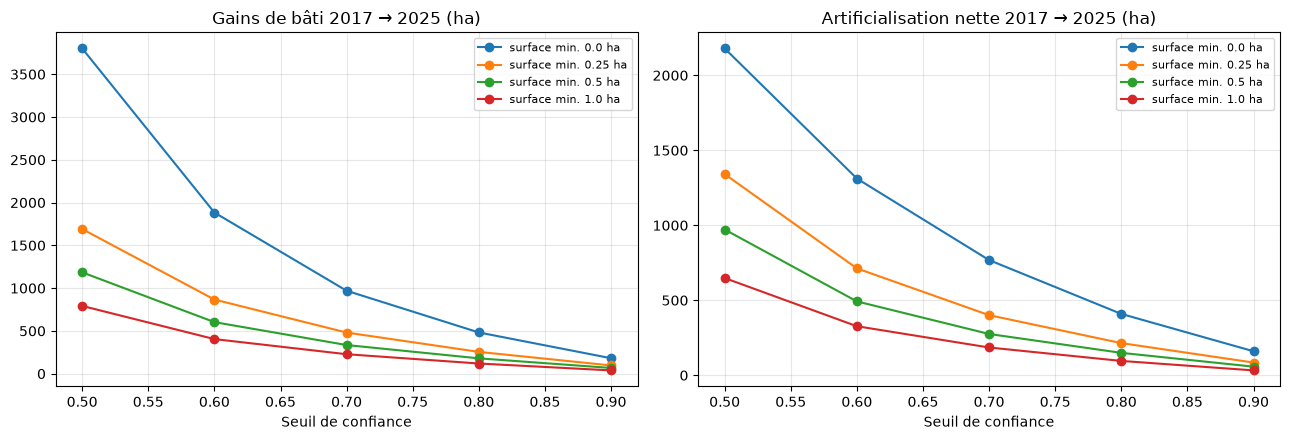

In [14]:
seuils = [0.5, 0.6, 0.7, 0.8, 0.9]
surfaces = [0.0, 0.25, 0.5, 1.0]
sens = np.zeros((len(surfaces), len(seuils), 2))
for i, s_min in enumerate(surfaces):
    for j, seuil in enumerate(seuils):
        r = resume("2017", "2025", flux("2017", "2025", seuil, s_min))
        sens[i, j] = r["gains_ha"], r["pertes_ha"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for i, s_min in enumerate(surfaces):
    axes[0].plot(seuils, sens[i, :, 0], "o-", label=f"surface min. {s_min} ha")
    axes[1].plot(seuils, sens[i, :, 0] - sens[i, :, 1], "o-", label=f"surface min. {s_min} ha")
axes[0].set_title("Gains de bâti 2017 → 2025 (ha)")
axes[1].set_title("Artificialisation nette 2017 → 2025 (ha)")
for ax in axes:
    ax.set_xlabel("Seuil de confiance")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(RES_DIR / "sensibilite_filtrage.png", dpi=120)
plt.show()

## 5. Cartes des changements

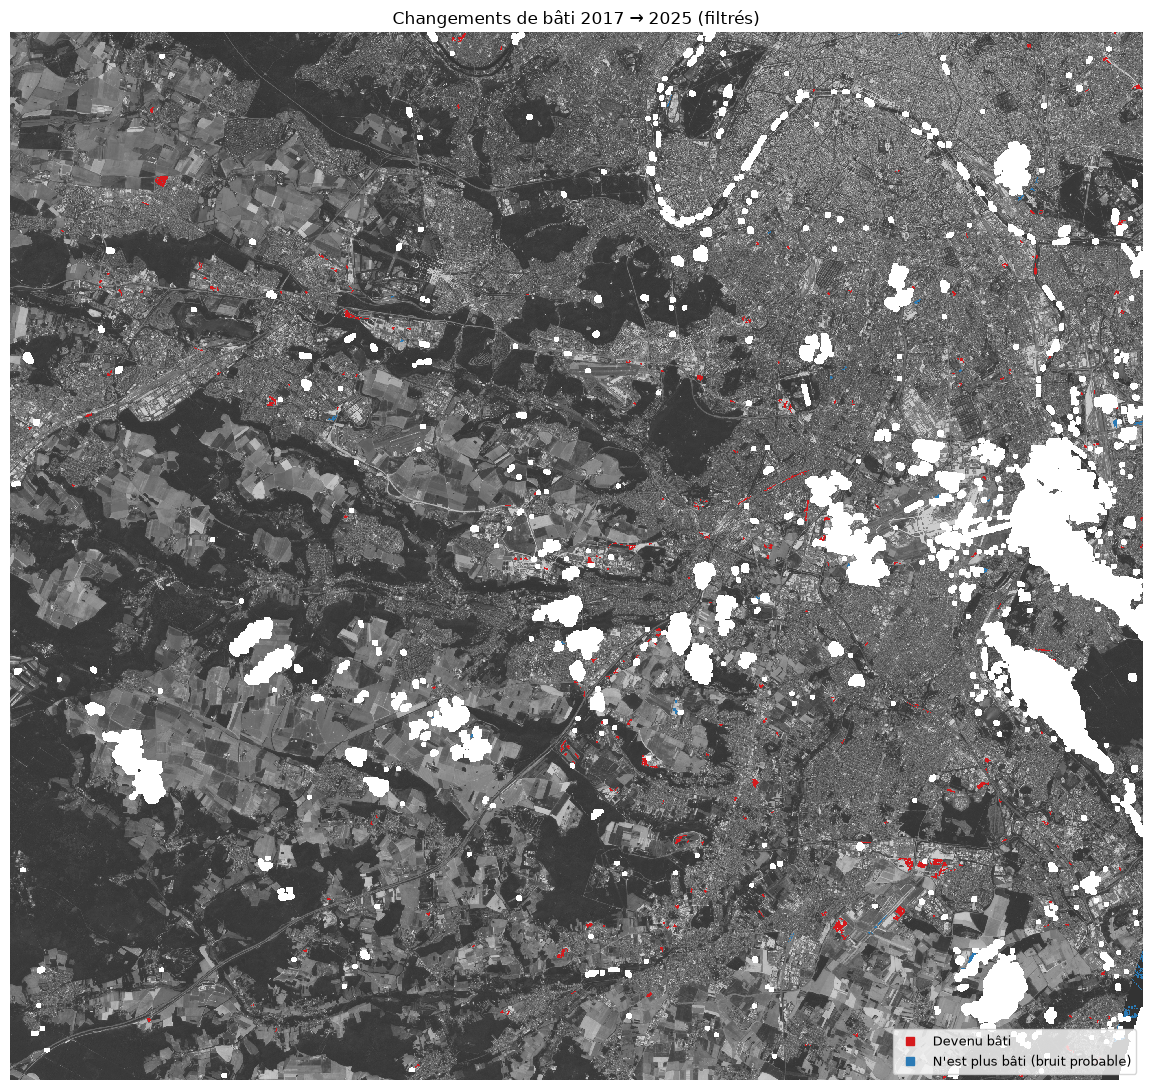

In [15]:
def fond_rgb(annee):
    with rasterio.open(DATA_DIR / f"s2_{annee}.tif") as src:
        img = np.moveaxis(src.read([3, 2, 1]).astype("float32"), 0, -1)
    bornes = np.percentile(img[img > 0], [2, 98])
    gris = np.clip((img - bornes[0]) / (bornes[1] - bornes[0]), 0, 1).mean(-1)
    return np.dstack([gris] * 3) * 0.6 + 0.2   # fond gris clair pour que le rouge et le bleu ressortent


def carte_changements(a, b, fenetre=None, ax=None, titre=""):
    f = flux_calcules[(a, b)]
    img = fond_rgb(b)
    img[~f["valide"]] = [1, 1, 1]
    img[f["gains"]] = [0.84, 0.10, 0.11]
    img[f["pertes"]] = [0.17, 0.48, 0.71]
    if fenetre is not None:
        img = img[fenetre]
    ax.imshow(img, interpolation="nearest")
    ax.plot([], [], "s", color=(0.84, 0.10, 0.11), label="Devenu bâti")
    ax.plot([], [], "s", color=(0.17, 0.48, 0.71), label="N'est plus bâti (bruit probable)")
    ax.legend(loc="lower right", fontsize=9)
    ax.set_title(titre)
    ax.axis("off")


fig, ax = plt.subplots(figsize=(12, 11))
carte_changements("2017", "2025", ax=ax, titre="Changements de bâti 2017 → 2025 (filtrés)")
plt.tight_layout()
plt.savefig(RES_DIR / "carte_changements.png", dpi=130, bbox_inches="tight")
plt.show()

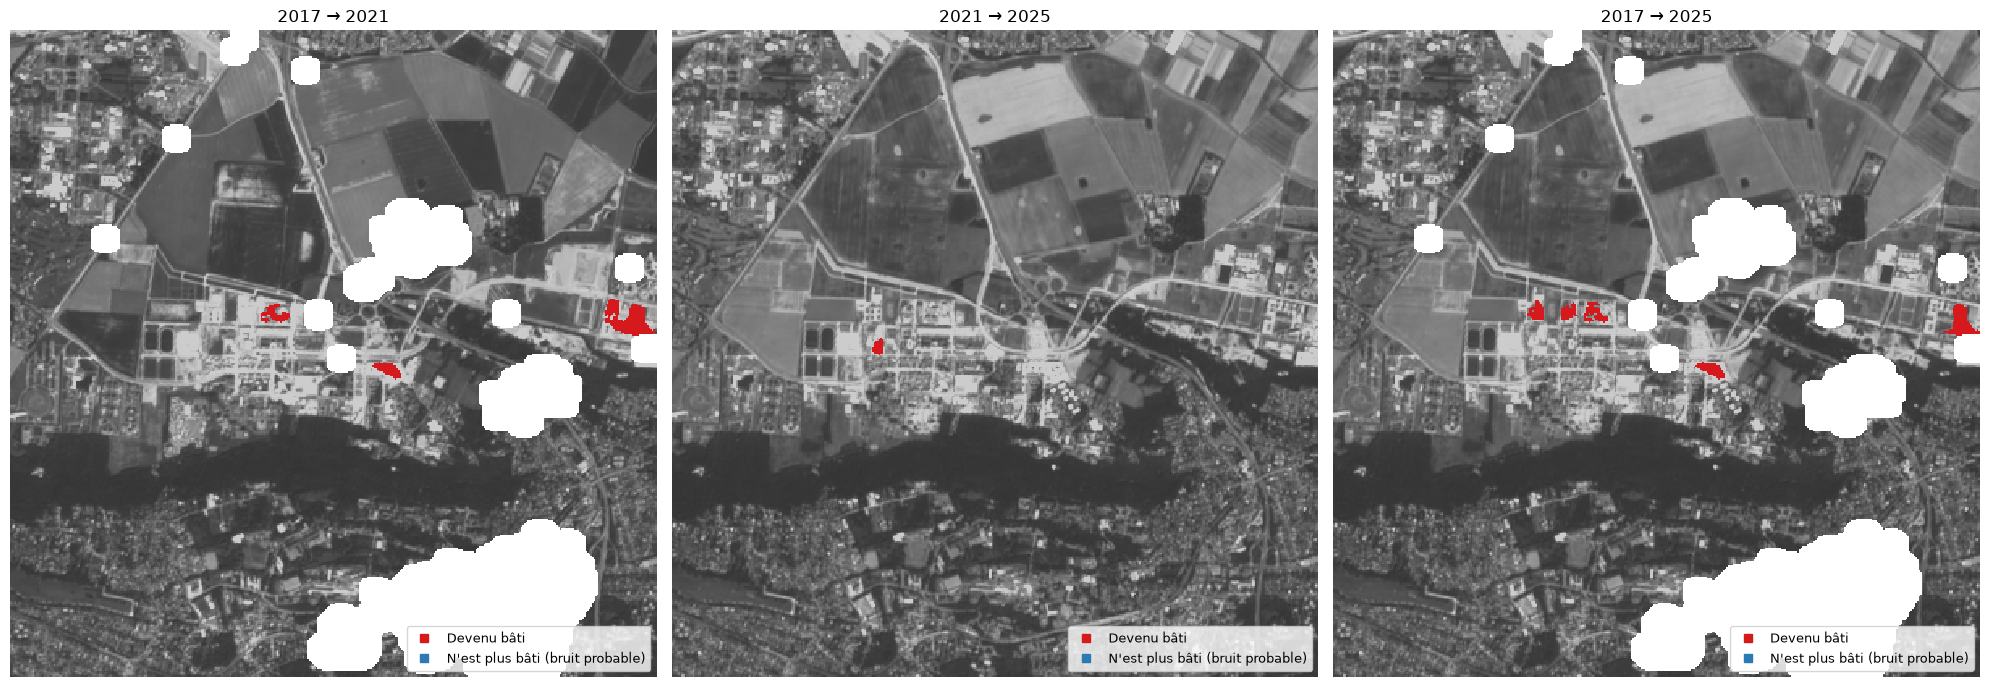

In [16]:
# zoom sur le plateau, même fenêtre que dans le 03 pour pouvoir comparer
from rasterio.warp import transform

with rasterio.open(CARTES_DIR / "occupation_2017.tif") as src:
    xs, ys = transform("EPSG:4326", src.crs, [2.17], [48.712])
    ligne, col = src.index(xs[0], ys[0])
T = 400
zone = (slice(max(ligne - T // 2, 0), ligne + T // 2), slice(max(col - T // 2, 0), col + T // 2))

fig, axes = plt.subplots(1, 3, figsize=(20, 7))
for ax, (a, b) in zip(axes, periodes):
    carte_changements(a, b, fenetre=zone, ax=ax, titre=f"{a} → {b}")
plt.tight_layout()
plt.savefig(RES_DIR / "zoom_changements.png", dpi=120, bbox_inches="tight")
plt.show()

## 6. Validation visuelle

Pas de donnée de référence indépendante pour 2017 et 2025 : j'ai vérifié à l'œil un échantillon de taches « devenu bâti » sur les images 2017 / 2025.

30 taches tirées **au hasard avec une probabilité proportionnelle à leur surface** : ça revient à tirer des hectares au hasard, ce qui permet d'estimer la part de la surface détectée qui correspond à de vrais changements (précision). Chaque vignette (≈ 600 m de côté, tache entourée en rouge) est classée en :
- `v` : vrai changement (construction, chantier, nouvelle route…)
- `f` : faux changement (rien n'a changé, ou changement qui n'est pas de l'artificialisation)
- `?` : impossible à trancher à 10 m

252 taches détectées, 30 tirées pour la validation


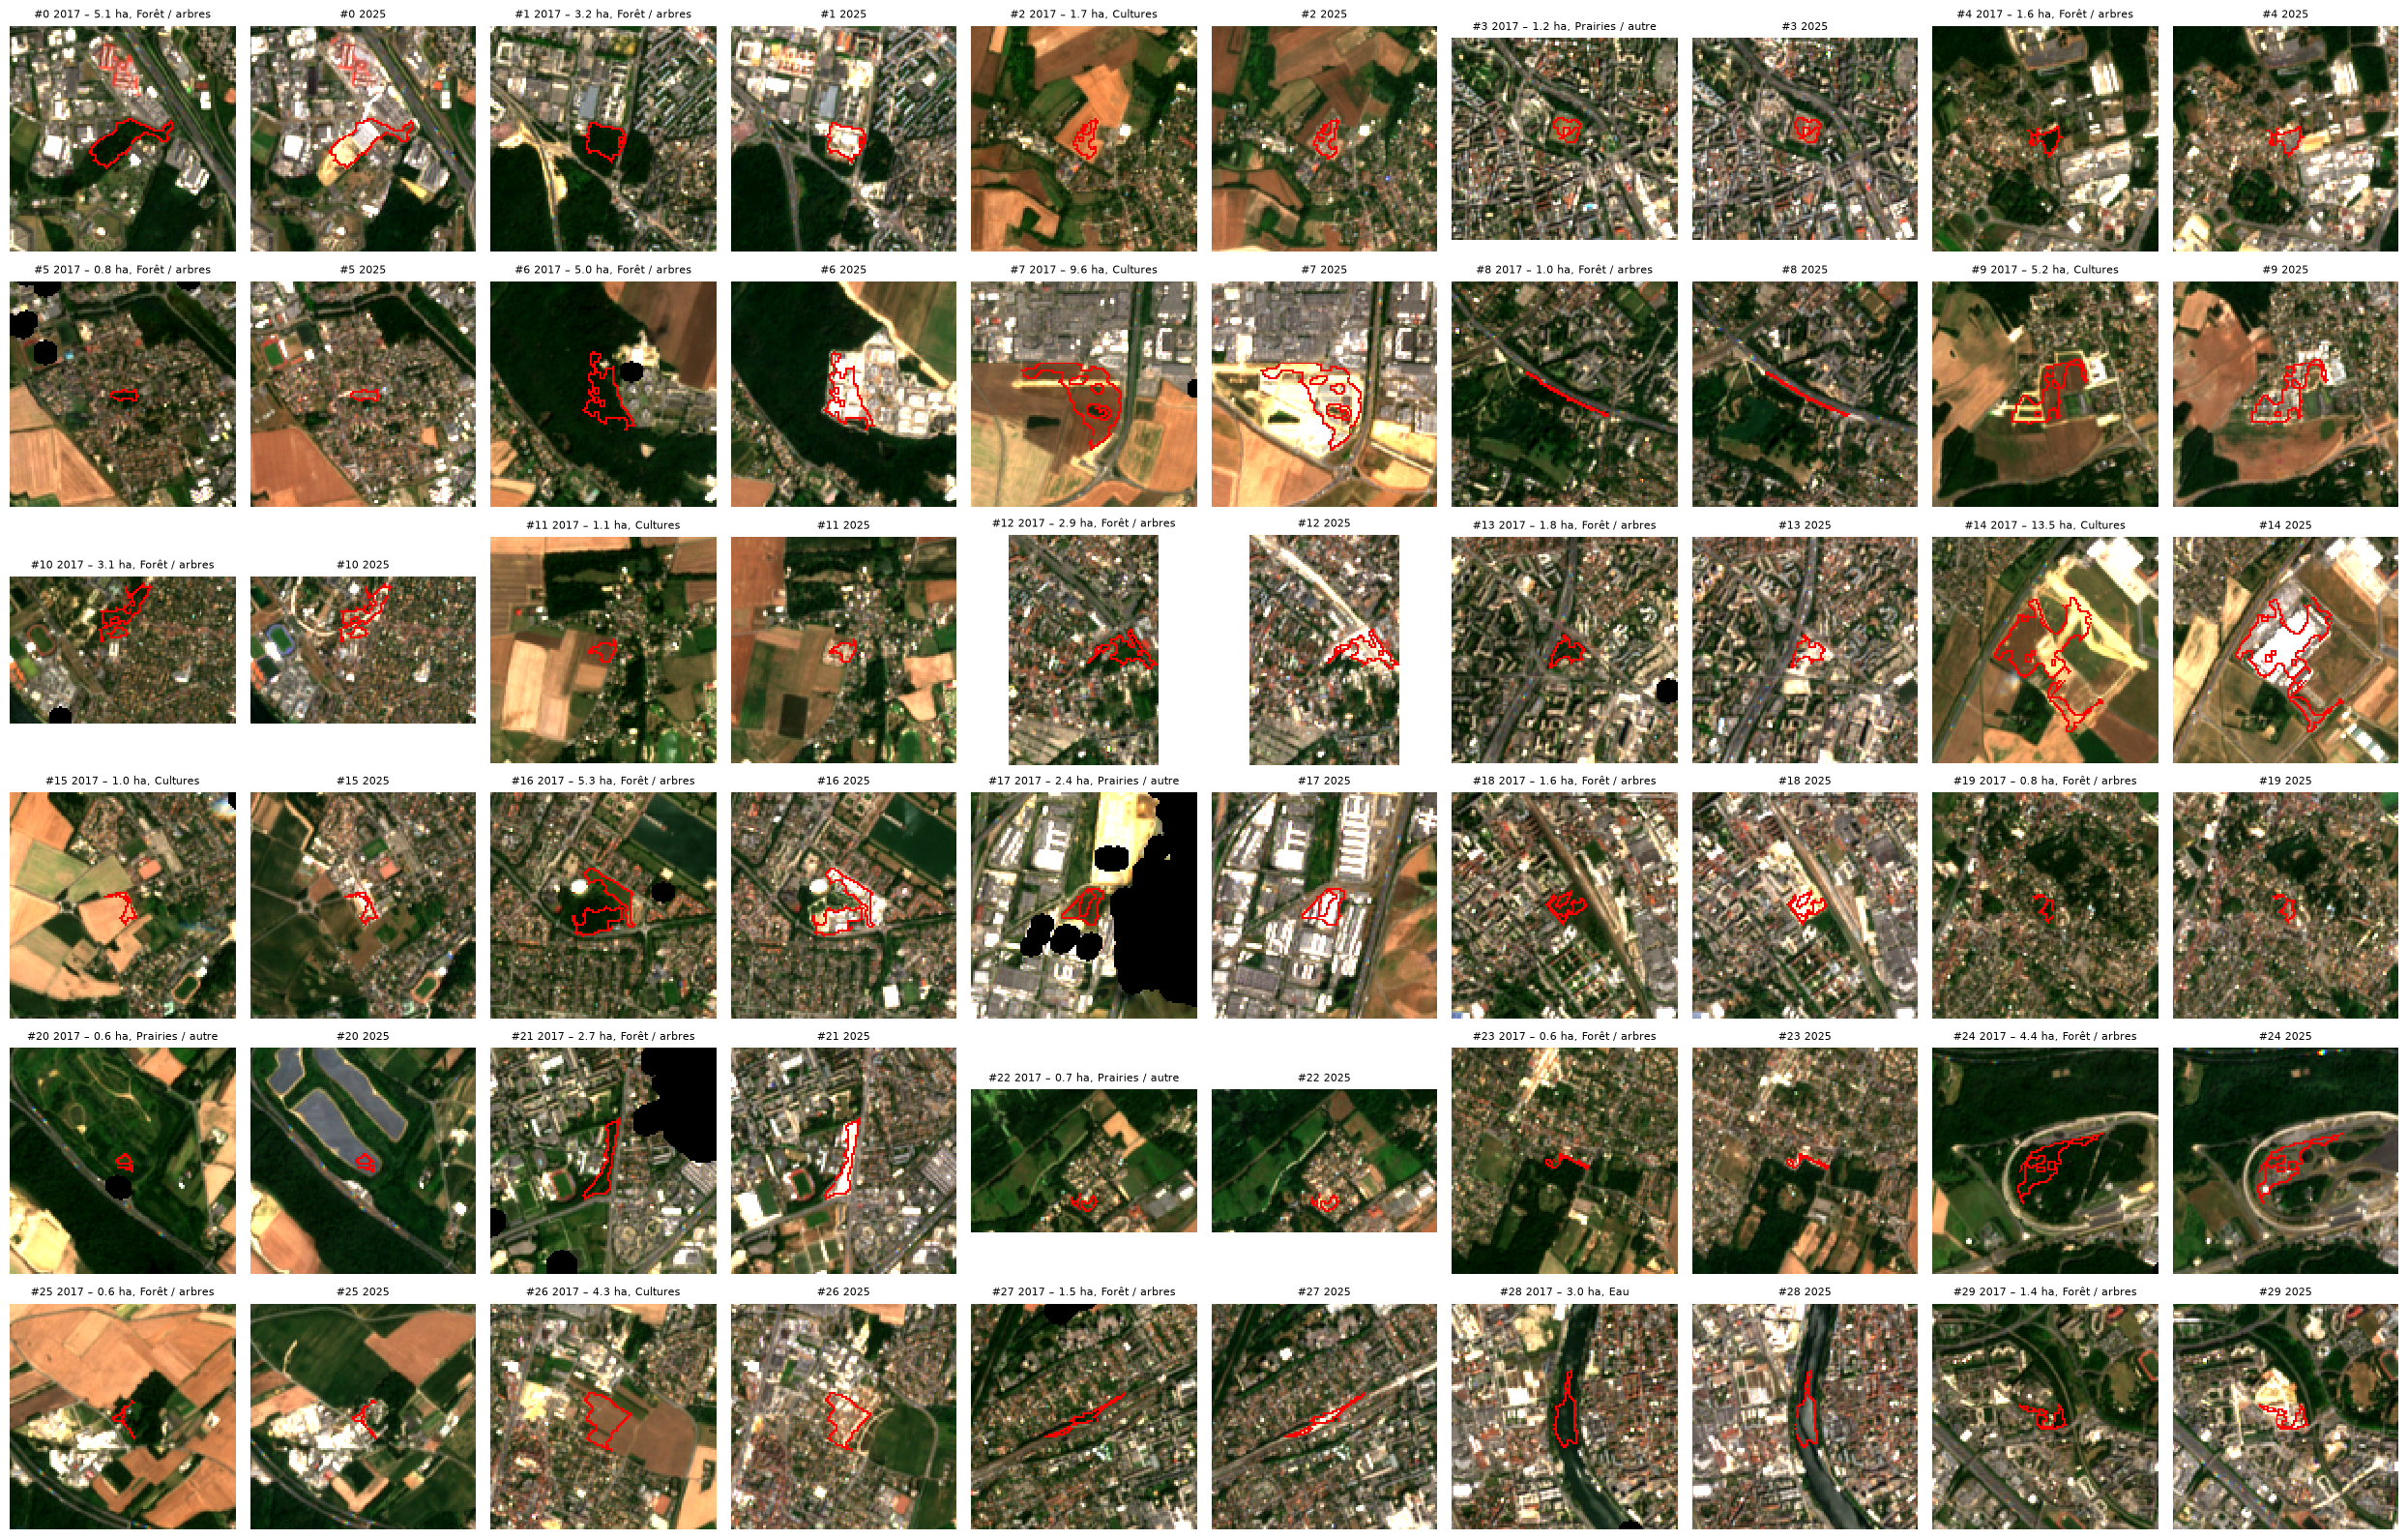

In [17]:
N_VALID = 30
TAILLE = 60   # demi-côté des vignettes en pixels (60 px = 600 m)

f = flux_calcules[("2017", "2025")]
n, etiq, stats, centres = cv2.connectedComponentsWithStats(f["gains"].astype(np.uint8), connectivity=8)
aires = stats[1:, cv2.CC_STAT_AREA].astype(float)        # composante 0 = fond
rng = np.random.default_rng(0)
choix = rng.choice(np.arange(1, n), size=min(N_VALID, n - 1), replace=False, p=aires / aires.sum())
print(f"{n - 1} taches détectées, {len(choix)} tirées pour la validation")


def rgb_complet(annee):
    with rasterio.open(DATA_DIR / f"s2_{annee}.tif") as src:
        img = np.moveaxis(src.read([3, 2, 1]).astype("float32"), 0, -1)
    bornes = np.percentile(img[img > 0], [2, 98])
    return np.clip((img - bornes[0]) / (bornes[1] - bornes[0]), 0, 1)

rgb = {a: rgb_complet(a) for a in ["2017", "2025"]}

echantillon = []
fig, axes = plt.subplots(6, 10, figsize=(25, 16))
for k, comp in enumerate(choix):
    cx, cy = centres[comp].astype(int)
    y0, y1 = max(cy - TAILLE, 0), min(cy + TAILLE, H)
    x0, x1 = max(cx - TAILLE, 0), min(cx + TAILLE, W)
    tache = etiq[y0:y1, x0:x1] == comp
    contour = tache & ~cv2.erode(tache.astype(np.uint8), np.ones((3, 3), np.uint8)).astype(bool)
    classe_origine = np.bincount(cartes["2017"][etiq == comp], minlength=256)[:5].argmax()
    echantillon.append({"id": k, "surface_ha": float(stats[comp, cv2.CC_STAT_AREA] * HA_PIXEL),
                        "origine": NOMS_CLASSES[classe_origine], "centre_px": [int(cx), int(cy)]})
    for j, annee in enumerate(["2017", "2025"]):
        ax = axes.ravel()[2 * k + j]
        vignette = rgb[annee][y0:y1, x0:x1].copy()
        vignette[contour] = [1, 0, 0]
        ax.imshow(vignette, interpolation="nearest")
        ax.set_title(f"#{k} {annee}" + (f" – {echantillon[-1]['surface_ha']:.1f} ha, {NOMS_CLASSES[classe_origine]}" if j == 0 else ""),
                     fontsize=8)
        ax.axis("off")
for ax in axes.ravel()[2 * len(choix):]:
    ax.axis("off")
plt.tight_layout()
plt.savefig(RES_DIR / "validation_vignettes.png", dpi=110, bbox_inches="tight")
plt.show()

Verdicts (dans l'ordre des vignettes #0 à #29), après examen des vignettes agrandies :

In [18]:
VERDICTS = "vvvfv?vv?vvvvvvvvvv?vv?fv?vvfv"   # v = vrai, f = faux, ? = indécis

assert len(VERDICTS) == len(echantillon), f"{len(VERDICTS)} verdicts pour {len(echantillon)} vignettes"
for e, v in zip(echantillon, VERDICTS):
    e["verdict"] = v

juges = [e for e in echantillon if e["verdict"] in "vf"]
vrais = [e for e in juges if e["verdict"] == "v"]
precision = len(vrais) / len(juges)
# IC à 95 % (approx. normale : un peu limite avec 25 vignettes, mais ça donne l'ordre de grandeur)
ic = 1.96 * np.sqrt(precision * (1 - precision) / len(juges))
print(f"Précision estimée : {len(vrais)}/{len(juges)} = {precision:.0%} (IC 95 % : {max(precision - ic, 0):.0%} – {min(precision + ic, 1):.0%})")
print(f"Indécis : {sum(e['verdict'] == '?' for e in echantillon)}")

print("\nPar classe d'origine :")
for nom in NOMS_CLASSES[1:]:
    sous = [e for e in juges if e["origine"] == nom]
    if sous:
        print(f"  {nom:18s} {sum(e['verdict'] == 'v' for e in sous)}/{len(sous)} vrais")

r = resume("2017", "2025", f)
gains_corriges = r["gains_ha"] * precision
print(f"\nGains 2017-2025 corrigés de la précision : {r['gains_ha']:.0f} ha x {precision:.0%} = {gains_corriges:.0f} ha "
      f"(soit {gains_corriges / 8:.0f} ha/an)")

with open(RES_DIR / "validation.json", "w", encoding="utf-8") as fp:
    json.dump({"precision": precision, "ic95": [max(precision - ic, 0), min(precision + ic, 1)],
               "gains_corriges_ha": gains_corriges, "echantillon": echantillon}, fp, indent=2, ensure_ascii=False)

Précision estimée : 22/25 = 88% (IC 95 % : 75% – 100%)
Indécis : 5

Par classe d'origine :
  Forêt / arbres     13/14 vrais
  Cultures           7/7 vrais
  Prairies / autre   2/3 vrais
  Eau                0/1 vrais

Gains 2017-2025 corrigés de la précision : 335 ha x 88% = 295 ha (soit 37 ha/an)


## 7. Évolution en pourcentage

Pour le rapport je voulais aussi un graphique en %, plus parlant que des hectares. Je prends la surface bâtie de 2017 comme référence et pour chaque année je compare directement à 2017 (donc le point 2025 n'est pas la somme des deux sous-périodes). La barre d'erreur, c'est la fourchette trouvée en section 4 : 180 à 400 ha à confiance 0,7.

findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Fon

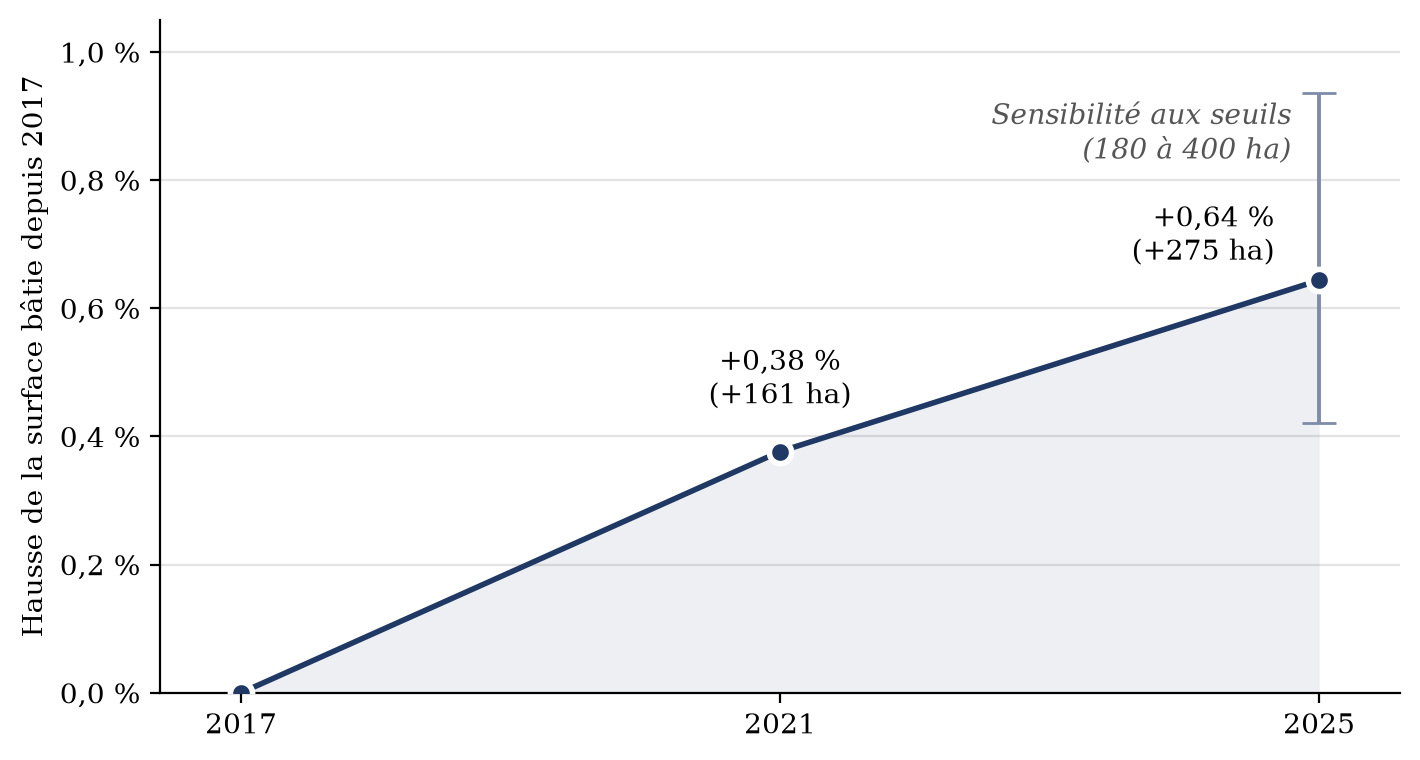

Surface bâtie 2017 (zone valide) : 42738 ha


In [19]:
bati_2017 = flux_calcules[("2017", "2025")]["bati_initial_ha"]
net = {"2017": 0.0, "2021": resultats[0]["net_ha"], "2025": resultats[2]["net_ha"]}
annees = [2017, 2021, 2025]
pct = [net[str(a)] / bati_2017 * 100 for a in annees]
bas, haut = 180 / bati_2017 * 100, 400 / bati_2017 * 100   # fourchette trouvée en section 4
virgule = lambda v, n=2: f"{v:.{n}f}".replace(".", ",")

fig, ax = plt.subplots(figsize=(7.2, 3.9), dpi=200)
ax.fill_between(annees, 0, pct, color="#1F3864", alpha=0.08, lw=0)
ax.plot(annees, pct, color="#1F3864", lw=2, marker="o", ms=8, mec="white", mew=2, zorder=3)
ax.errorbar([2025], [pct[2]], yerr=[[pct[2] - bas], [haut - pct[2]]], fmt="none", ecolor="#7F8BA8", elinewidth=1.4, capsize=6)
ax.annotate(f"+{virgule(pct[1])} %\n(+{net['2021']:.0f} ha)", (2021, pct[1]), xytext=(0, 14), textcoords="offset points", ha="center", va="bottom")
ax.annotate(f"+{virgule(pct[2])} %\n(+{net['2025']:.0f} ha)", (2025, pct[2]), xytext=(-16, 4), textcoords="offset points", ha="right", va="bottom")
ax.annotate("Sensibilité aux seuils\n(180 à 400 ha)", (2025, haut), xytext=(-10, -2), textcoords="offset points",
            ha="right", va="top", fontsize=10, color="#555", style="italic")
ax.set_xticks(annees); ax.set_xlim(2016.4, 2025.6); ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: virgule(v, 1) + " %"))
ax.set_ylabel("Hausse de la surface bâtie depuis 2017")
ax.grid(axis="y", color="#E3E3E3", lw=0.8); ax.set_axisbelow(True)
for c in ["top", "right"]: ax.spines[c].set_visible(False)
plt.tight_layout()
plt.savefig(RES_DIR / "evolution_artificialisation.png")
plt.show()
print(f"Surface bâtie 2017 (zone valide) : {bati_2017:.0f} ha")

## 8. Par commune et comparaison avec le Cerema

Un total sur mon rectangle de 1 460 km² ne veut pas dire grand-chose : le ZAN se gère par commune et par interco (PLU, PLUi, SCoT). Donc je ventile les flux 2017 → 2025 par commune, et je compare avec la consommation d'espaces NAF du Cerema (calculée à partir des fichiers fonciers), qui est la donnée officielle pour suivre le ZAN.

Fichiers que j'ai ajoutés dans `data_saclay/` :
- `communes_zone.geojson` : contours IGN Admin Express 2018 (version simplifiée de [france-geojson](https://github.com/gregoiredavid/france-geojson)), seulement les communes qui touchent ma zone ;
- `cerema_conso_zone.csv` : extrait du [fichier communal du Cerema](https://www.data.gouv.fr/fr/datasets/6a01b9280dd2d45907e5fc61/) pour ces communes (valeurs en m²).

À garder en tête : ce n'est pas la même mesure. Le Cerema compte toute la parcelle (jardin, parking…) quand elle passe en urbanisé dans le cadastre, en général une fois les travaux finis. Moi je détecte ce qui *ressemble* à du bâti, dès le chantier. Je regarde donc surtout si les ordres de grandeur et la localisation collent, pas si les chiffres sont égaux.

In [20]:
import geopandas as gpd
import pandas as pd
from rasterio.features import rasterize

communes = gpd.read_file(DATA_DIR / "communes_zone.geojson")
# 3 communes ont fusionné depuis 2018 -> je les rattache à la commune actuelle
FUSIONS = {"78251": "78551",   # Fourqueux -> Saint-Germain-en-Laye
           "78524": "78158",   # Rocquencourt -> Le Chesnay-Rocquencourt
           "91182": "91228"}   # Courcouronnes -> Évry-Courcouronnes
communes["code"] = communes["code"].replace(FUSIONS)
communes = communes.dissolve(by="code", as_index=False).to_crs(profil["crs"])
communes["id"] = np.arange(1, len(communes) + 1)

# chaque pixel va à la commune qui contient son centre
id_commune = rasterize(zip(communes.geometry, communes["id"]), out_shape=(H, W),
                       transform=profil["transform"], fill=0, dtype="int32")
print(f"{len(communes)} communes, {(id_commune > 0).mean():.1%} des pixels affectés à une commune")

231 communes, 100.0% des pixels affectés à une commune


In [21]:
cerema = pd.read_csv(DATA_DIR / "cerema_conso_zone.csv", dtype={"idcom": str}).set_index("idcom")
ANNEES = range(17, 25)   # 1er janv. 2017 -> 1er janv. 2025, le plus proche de mes images
cerema["cerema_ha"] = sum(cerema[f"naf{a}art{a + 1}"] for a in ANNEES) / 1e4
cerema["cerema_activite_ha"] = sum(cerema[f"art{a}act{a + 1}"] for a in ANNEES) / 1e4
cerema["cerema_habitat_ha"] = sum(cerema[f"art{a}hab{a + 1}"] for a in ANNEES) / 1e4
cerema["surface_ha"] = cerema["surfcom2025"] / 1e4


def par_commune(masque):
    return np.bincount(id_commune[masque], minlength=len(communes) + 1)[1:] * HA_PIXEL


f = flux_calcules[("2017", "2025")]
communes["gains_ha"] = par_commune(f["gains"])
communes["pertes_ha"] = par_commune(f["pertes"])
communes["net_ha"] = communes["gains_ha"] - communes["pertes_ha"]
communes["analyse_ha"] = par_commune(f["valide"])
communes = communes.join(cerema[["idcomtxt", "epci25txt", "surface_ha", "cerema_ha", "cerema_activite_ha", "cerema_habitat_ha"]], on="code")
communes["couverture"] = communes["analyse_ha"] / communes["surface_ha"]

# vérif : la somme par commune doit redonner le total de la section 2
print(f"Gains : {communes['gains_ha'].sum():.1f} ha (total {f['gains'].sum() * HA_PIXEL:.1f} ha)")

# je garde seulement les communes vues à au moins 90 % (les autres sont coupées par le bord ou les nuages)
ok = communes[communes["couverture"] >= 0.9].copy()
print(f"{len(ok)} communes couvertes à 90 % ou plus, {ok['gains_ha'].sum() / communes['gains_ha'].sum():.0%} des gains")
top = ok.sort_values("net_ha", ascending=False).head(10)
print(f"Les 10 premières font {top['net_ha'].sum() / ok['net_ha'].sum():.0%} du net")
top[["idcomtxt", "epci25txt", "net_ha", "cerema_ha"]].round(1)

Gains : 334.8 ha (total 334.8 ha)
147 communes couvertes à 90 % ou plus, 79% des gains
Les 10 premières font 54% du net


,idcomtxt,epci25txt,net_ha,cerema_ha
136,Le Plessis-Pâté,CA Coeur d'Essonne Agglomération,21.2,72.1
119,Marcoussis,CA Communauté Paris-Saclay,18.4,73.1
80,Brétigny-sur-Orge,CA Coeur d'Essonne Agglomération,16.0,44.0
121,Massy,CA Communauté Paris-Saclay,14.3,12.4
100,Fleury-Mérogis,CA Coeur d'Essonne Agglomération,13.8,13.2
68,Villepreux,CA de Saint Quentin en Yvelines,11.0,14.9
133,Palaiseau,CA Communauté Paris-Saclay,9.8,47.2
78,Bondoufle,CA Grand Paris Sud Seine Essonne Sénart,9.3,26.6
66,Versailles,CA Versailles Grand Parc (CAVGP),9.0,1.6
175,Châtenay-Malabry,Métropole du Grand Paris,8.0,1.4


In [23]:
from math import erfc, sqrt

rho = ok["net_ha"].rank().corr(ok["cerema_ha"].rank())   # Spearman = Pearson sur les rangs (pas de scipy dans mon venv)
t = rho * sqrt((len(ok) - 2) / (1 - rho ** 2))
p = erfc(abs(t) / sqrt(2))   # approx. normale, ça suffit avec ~150 communes
print(f"Total : {ok['net_ha'].sum():.0f} ha mesurés contre {ok['cerema_ha'].sum():.0f} ha Cerema "
      f"({ok['net_ha'].sum() / ok['cerema_ha'].sum():.0%})")
print(f"  dont activité {ok['cerema_activite_ha'].sum():.0f} ha et habitat {ok['cerema_habitat_ha'].sum():.0f} ha côté Cerema")
print(f"Spearman : rho = {rho:.2f} (p ≈ {p:.0e})")
fortes = ok[ok["cerema_ha"] >= 10]
print(f"Communes à ≥ 10 ha selon le Cerema : {len(fortes)}, dont {(fortes['gains_ha'] > 0).sum()} avec au moins une tache détectée")

# intercos entièrement dans la zone (sinon la comparaison n'a pas de sens)
toutes = pd.read_csv(DATA_DIR / "cerema_conso_zone.csv", usecols=["epci25txt", "nb_communes_epci"]).drop_duplicates()
epci = communes.groupby("epci25txt").agg(communes=("code", "size"), analyse_ha=("analyse_ha", "sum"), surface_ha=("surface_ha", "sum"),
                                         net_ha=("net_ha", "sum"), cerema_ha=("cerema_ha", "sum"))
epci = epci.join(toutes.set_index("epci25txt"))
epci = epci[epci["communes"] == epci["nb_communes_epci"]]
epci["couverture"] = epci["analyse_ha"] / epci["surface_ha"]
epci["rapport"] = epci["net_ha"] / epci["cerema_ha"]
epci.sort_values("net_ha", ascending=False)[["communes", "couverture", "net_ha", "cerema_ha", "rapport"]].round(2)

Total : 243 ha mesurés contre 901 ha Cerema (27%)
  dont activité 492 ha et habitat 299 ha côté Cerema
Spearman : rho = 0.49 (p ≈ 1e-11)
Communes à ≥ 10 ha selon le Cerema : 26, dont 25 avec au moins une tache détectée


,communes,couverture,net_ha,cerema_ha,rapport
epci25txt,,,,,
CA Communauté Paris-Saclay,27,0.93,78.20,413.91,0.19
CA Coeur d'Essonne Agglomération,21,0.94,76.28,271.01,0.28
CA de Saint Quentin en Yvelines,12,0.93,30.52,97.62,0.31
CA Versailles Grand Parc (CAVGP),18,0.99,21.45,37.12,0.58
CC du Pays de Limours (CCPL),14,0.95,4.53,49.26,0.09
CC de la Haute Vallée de Chevreuse,10,0.97,0.66,13.49,0.05


findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Fon

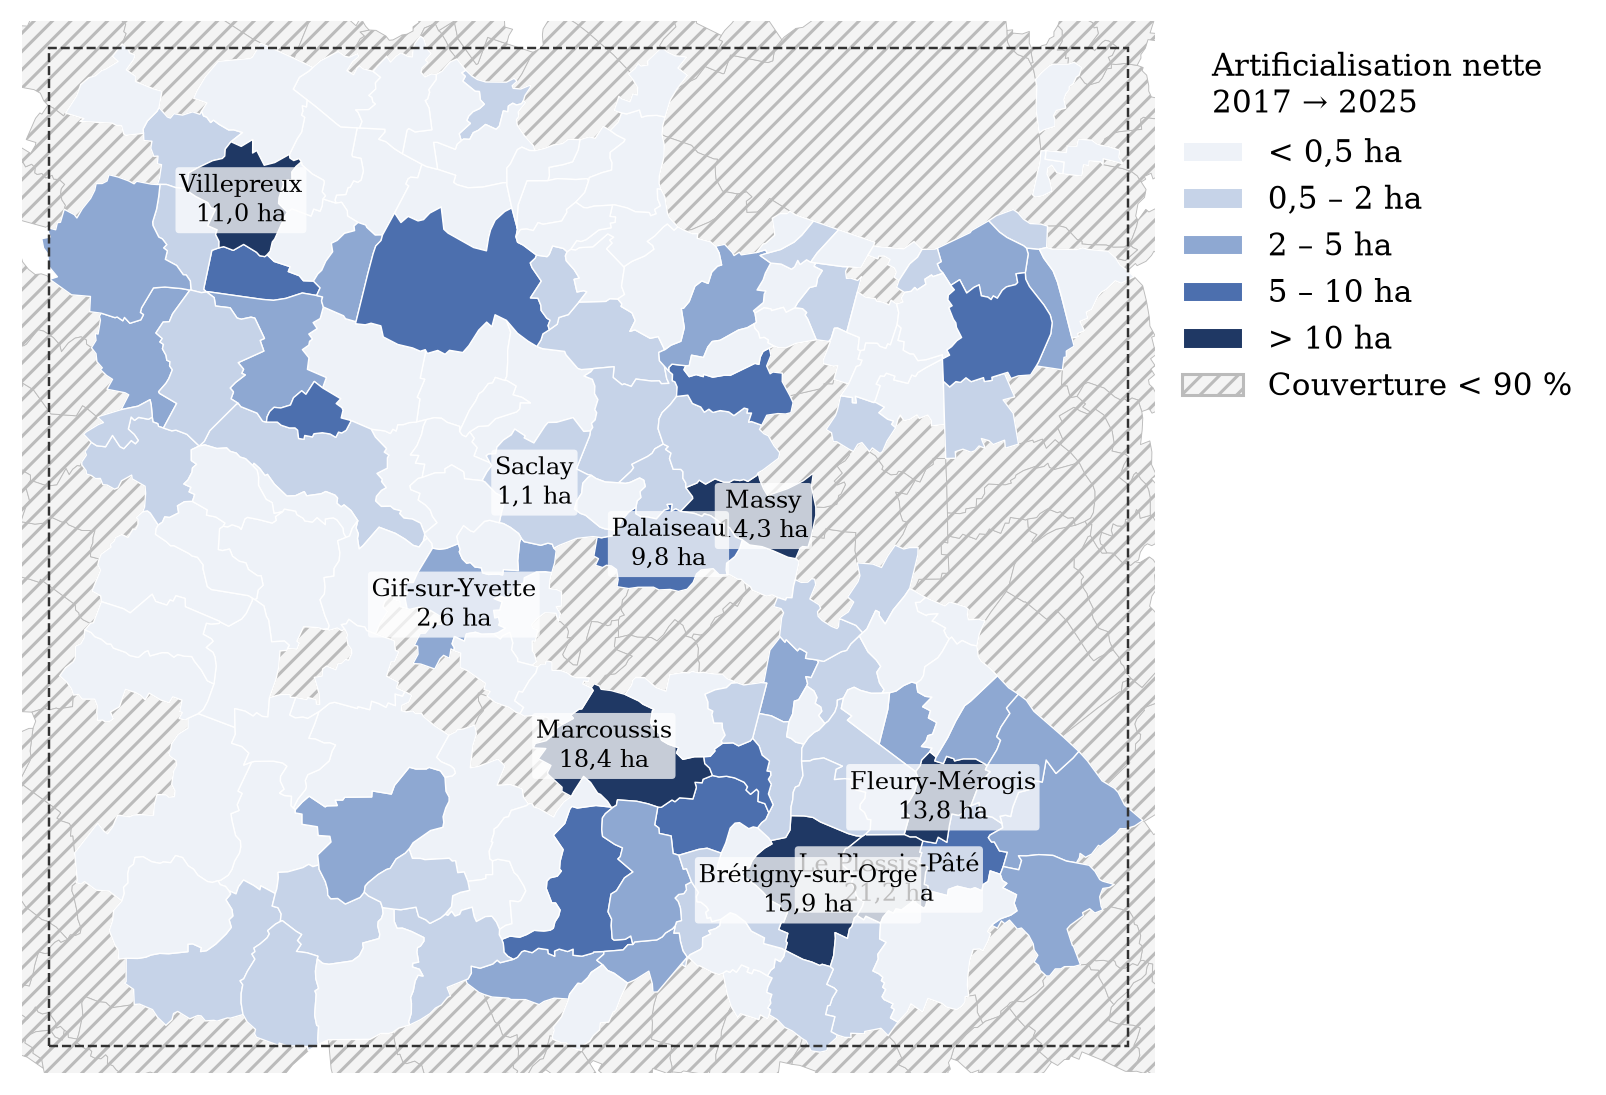

In [24]:
from matplotlib import patheffects
from matplotlib.patches import Patch

bornes = [0.5, 2, 5, 10]
couleurs = ["#EEF2F8", "#C6D3E8", "#8EA8D2", "#4C6FAE", "#1F3864"]
etiquettes = ["< 0,5 ha", "0,5 – 2 ha", "2 – 5 ha", "5 – 10 ha", "> 10 ha"]
ok["classe"] = np.digitize(ok["net_ha"], bornes)

fig, ax = plt.subplots(figsize=(7.4, 7), dpi=220)
communes[communes["couverture"] < 0.9].plot(ax=ax, facecolor="#F4F4F4", edgecolor="#BBBBBB", linewidth=0.3, hatch="////")
ok.plot(ax=ax, color=[couleurs[k] for k in ok["classe"]], edgecolor="white", linewidth=0.45)
x0, y0 = profil["transform"].c, profil["transform"].f
ax.add_patch(plt.Rectangle((x0, y0 - H * 10), W * 10, H * 10, fill=False, ec="#333", lw=0.8, ls="--"))
ax.set_xlim(x0 - 1000, x0 + W * 10 + 1000); ax.set_ylim(y0 - H * 10 - 1000, y0 + 1000)
# étiquettes décalées à la main (en km) sinon ça se chevauche au sud-est
DECALAGE = {"Brétigny-sur-Orge": (-4.5, -3.2), "Le Plessis-Pâté": (4.5, -3.5), "Fleury-Mérogis": (4.8, 2.2),
            "Villepreux": (0, 3.2), "Massy": (3.8, 1.6), "Marcoussis": (-1.5, 2.6)}
for _, r in pd.concat([top.head(7), ok[ok["idcomtxt"].isin(["Saclay", "Gif-sur-Yvette"])]]).iterrows():
    pt = r.geometry.representative_point()
    dx, dy = DECALAGE.get(r["idcomtxt"], (0, 0))
    txt = ax.annotate(f"{r['idcomtxt']}\n{r['net_ha']:.1f} ha".replace(".", ","), (pt.x, pt.y),
                      xytext=(pt.x + dx * 1000, pt.y + dy * 1000), ha="center", va="center", fontsize=8, linespacing=0.95,
                      arrowprops=dict(arrowstyle="-", color="#333", lw=0.6) if (dx or dy) else None)
    txt.set_path_effects([patheffects.withStroke(linewidth=2.6, foreground="white")])
legende = [Patch(fc=c, ec="white", label=l) for c, l in zip(couleurs, etiquettes)]
legende.append(Patch(fc="#F4F4F4", ec="#BBBBBB", hatch="////", label="Couverture < 90 %"))
ax.legend(handles=legende, title="Artificialisation nette\n2017 → 2025", loc="upper left", bbox_to_anchor=(1, 1), frameon=False)
ax.axis("off")
plt.tight_layout()
plt.savefig(RES_DIR / "artificialisation_communes.png", bbox_inches="tight")
plt.show()

findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Fon

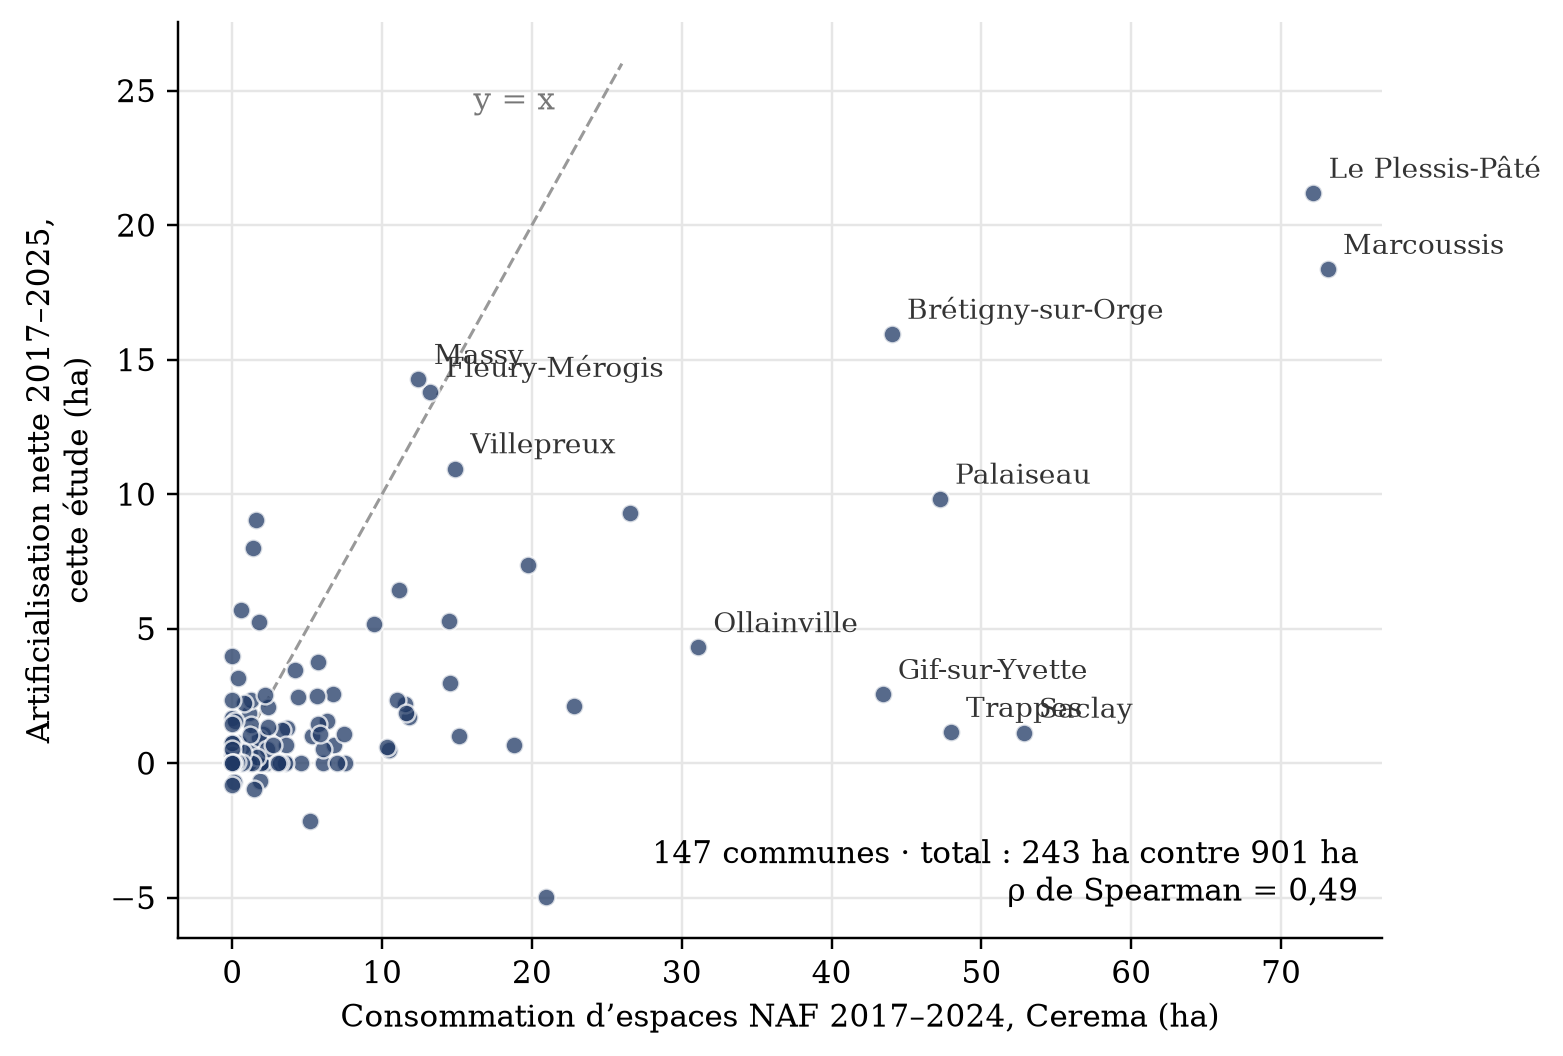

In [25]:
fig, ax = plt.subplots(figsize=(7.2, 4.9), dpi=220)
ax.plot([0, 26], [0, 26], color="#999", lw=1, ls="--")
ax.text(21.5, 24.3, "y = x", color="#777", fontsize=10, ha="right")
ax.scatter(ok["cerema_ha"], ok["net_ha"], s=34, color="#1F3864", alpha=0.75, ec="white", lw=0.8, zorder=3)
# décalages placés à la main (en points) pour que les noms ne se chevauchent pas
a_nommer = {"Saclay": (4, 6), "Trappes": (-8, -4), "Gif-sur-Yvette": (-4, 8), "Palaiseau": (4, 6), "Marcoussis": (-8, -14),
            "Le Plessis-Pâté": (-6, 6), "Brétigny-sur-Orge": (6, -6), "Massy": (-6, 8), "Villepreux": (6, 2),
            "Fleury-Mérogis": (8, -4), "Ollainville": (4, 4)}
for _, r in ok[ok["idcomtxt"].isin(a_nommer)].iterrows():
    dx, dy = a_nommer[r["idcomtxt"]]
    ax.annotate(r["idcomtxt"], (r["cerema_ha"], r["net_ha"]), xytext=(dx, dy), textcoords="offset points", fontsize=9, color="#333",
                ha="left" if dx >= 0 else "right", va="center",
                arrowprops=dict(arrowstyle="-", color="#aaa", lw=0.5, shrinkA=1, shrinkB=3))
ax.set_xlim(-2, 78); ax.set_ylim(-6, 26)
ax.set_xlabel("Consommation d’espaces NAF 2017–2024, Cerema (ha)")
ax.set_ylabel("Artificialisation nette 2017–2025,\ncette étude (ha)")
ax.text(0.98, 0.03, f"{len(ok)} communes · total : {ok['net_ha'].sum():.0f} ha contre {ok['cerema_ha'].sum():.0f} ha\n"
        f"ρ de Spearman = {rho:.2f}".replace(".", ","), transform=ax.transAxes, ha="right", va="bottom", fontsize=10)
ax.grid(color="#E6E6E6", lw=0.8); ax.set_axisbelow(True)
for c in ["top", "right"]: ax.spines[c].set_visible(False)
plt.tight_layout()
plt.savefig(RES_DIR / "comparaison_cerema.png")
plt.show()

communes.drop(columns="geometry").to_csv(RES_DIR / "artificialisation_communes.csv", index=False)

## 9. Sauvegarde

In [26]:
# je sauvegarde le raster des changements 2017 -> 2025 : 0 = pas de changement, 1 = devenu bâti, 2 = n'est plus bâti, 255 = non valide
f = flux_calcules[("2017", "2025")]
changements = np.zeros((H, W), np.uint8)
changements[f["gains"]] = 1
changements[f["pertes"]] = 2
changements[~f["valide"]] = 255
profil.update(dtype="uint8", nodata=255, count=1, compress="deflate")
with rasterio.open(CARTES_DIR / "changements_2017_2025.tif", "w", **profil) as dst:
    dst.write(changements, 1)

indicateurs = {
    "parametres": {"seuil_confiance": SEUIL_CONFIANCE, "surface_min_ha": SURFACE_MIN_HA, "marge_nodata_px": MARGE_NODATA},
    "flux": resultats,
    "origine_artificialisation_2017_2025_ha": origine_ha,
    "matrice_transition_2017_2025_ha": {"classes": NOMS_CLASSES, "valeurs": mat.round(1).tolist()},
}
with open(RES_DIR / "indicateurs.json", "w", encoding="utf-8") as fp:
    json.dump(indicateurs, fp, indent=2, ensure_ascii=False)
print(json.dumps(resultats, indent=2, ensure_ascii=False))

[
  {
    "periode": "2017-2021",
    "duree_ans": 4,
    "gains_bruts_ha": 3920.91,
    "pertes_brutes_ha": 4461.6900000000005,
    "gains_ha": 189.97,
    "pertes_ha": 29.060000000000002,
    "net_ha": 160.91,
    "net_ha_par_an": 40.2275,
    "taux_artificialisation": 0.003765165607852772,
    "part_zone_valide": 0.9416205707856221
  },
  {
    "periode": "2021-2025",
    "duree_ans": 4,
    "gains_bruts_ha": 7217.03,
    "pertes_brutes_ha": 3479.09,
    "gains_ha": 158.54,
    "pertes_ha": 82.16,
    "net_ha": 76.38,
    "net_ha_par_an": 19.095,
    "taux_artificialisation": 0.0016789813212778457,
    "part_zone_valide": 0.9999871041684969
  },
  {
    "periode": "2017-2025",
    "duree_ans": 8,
    "gains_bruts_ha": 5604.3,
    "pertes_brutes_ha": 2671.38,
    "gains_ha": 334.81,
    "pertes_ha": 59.620000000000005,
    "net_ha": 275.19,
    "net_ha_par_an": 34.39875,
    "taux_artificialisation": 0.00643893714367541,
    "part_zone_valide": 0.9416334666171252
  }
]


## Observations

**Artificialisation mesurée** (confiance ≥ 0,7, taches ≥ 0,5 ha) :

| Période | Gains | Pertes | Net | Net / an |
|---|---|---|---|---|
| 2017 → 2021 | 190 ha | 29 ha | 161 ha | 40 ha |
| 2021 → 2025 | 159 ha | 82 ha | 76 ha | 19 ha |
| **2017 → 2025** | **335 ha** | **60 ha** | **275 ha** | **34 ha** |

- La comparaison brute donne 5 604 ha de gains et 2 671 ha de pertes : c'est presque entièrement du bruit. Le filtrage en retire ~94 %.
- Les pertes restantes (bruit probable) font ~18 % des gains. Les deux sous-périodes sont cohérentes avec la période complète (161 + 76 = 237 ha contre 275 ha).
- 275 ha nets = +0,6 % de la surface bâtie de 2017.

**Origine des surfaces artificialisées** : forêt / arbres 156 ha (47 %), prairies / autre 96 ha (29 %), cultures 77 ha (23 %), eau 6 ha (2 %). Je m'attendais à une majorité de terres agricoles (campus, plateau) ; la forêt domine.

**Sensibilité** : le résultat dépend beaucoup des seuils. Avec une surface min. de 0,5 ha, le net va de ~970 ha (confiance 0,5) à ~60 ha (confiance 0,9) ; à confiance 0,7, de ~180 ha (1 ha) à ~400 ha (0,25 ha). Les 275 ha sont donc un ordre de grandeur (quelques centaines d'hectares), pas une valeur précise.

**Validation visuelle** : 22 vrais changements, 3 faux, 5 indécis → **précision ≈ 88 %** (22/25, IC 95 % : 75–100 %), soit ~295 ha de gains réellement artificialisés.
- vrais changements : entrepôts et zones d'activité, lotissements en bord de village, immeubles sur d'anciens parcs, chantiers, nouvelles pistes dans l'autodrome de Montlhéry, une centrale solaire au sol (#20, artificialisation discutable au sens du ZAN) ;
- faux : un terrain de sport inchangé (#3), une lisière de bois (#23), un tronçon de Seine (#28) ;
- indécis : surtout des petites taches en pavillonnaire, où toits et jardins se mélangent à 10 m.
- par origine : 7/7 vrais pour les cultures, 13/14 jugés pour la forêt. La part de forêt n'est donc pas un artefact : en banlieue dense, l'urbanisation se fait aussi en construisant sur les parcs, bosquets et lisières.

**Localisation** : changements dispersés sur toute la zone, avec des concentrations au sud-est (zones d'activité) et sur le plateau. Sur le campus, l'essentiel apparaît dès 2017–2021 : en juillet 2017 une partie des terrains était déjà en chantier, donc déjà classée en bâti. Pour le modèle, l'artificialisation commence au terrassement.

**Évolution en %** : +0,38 % du bâti de 2017 en 2021 (161 ha) et +0,64 % en 2025 (275 ha), sur ~42 700 ha de bâti. Ça monte plus vite sur 2017–2021, mais l'écart entre les deux périodes est du même ordre que l'incertitude due aux seuils, donc je ne peux pas vraiment parler de ralentissement.

**Par commune** (147 communes vues à 90 % ou plus, 79 % des gains) : c'est très concentré, les 10 premières font 54 % du net. En tête Le Plessis-Pâté (21 ha) et Brétigny (16 ha), autour de l'ancienne base aérienne 217, puis Marcoussis (18 ha) et Massy (14 ha). Saclay (1,1 ha) et Gif (2,6 ha) ressortent très peu, ce qui colle avec le campus déjà en chantier en 2017.

**Comparaison Cerema** : 243 ha chez moi contre 901 ha de conso NAF sur 2017–2024, donc je retrouve à peu près un quart. Les classements sont quand même corrélés (Spearman 0,49) et la localisation est bonne : sur les 26 communes à plus de 10 ha côté Cerema, 25 ont au moins une tache détectée. Par contre je sous-estime beaucoup les surfaces. Je vois trois raisons :
- le Cerema compte toute la parcelle (jardin, parking, voirie), moi seulement ce qui ressemble à du bâti, et en plus mon filtrage vire les petites taches ;
- le Cerema compte le changement quand les travaux sont finis, moi dès le chantier : ça explique sûrement Saclay (1 contre 53 ha), Gif (3 contre 43 ha) et Palaiseau (10 contre 47 ha) ;
- dans le rural boisé (Haute Vallée de Chevreuse, Pays de Limours) je ne retrouve que 5 à 9 % : les maisons isolées sous les arbres, à 10 m je ne les vois pas.

À l'inverse en ville dense (Versailles : 9 ha contre 2 ha), je détecte des constructions sur des terrains déjà urbanisés, que le Cerema ne compte pas puisque ce n'était pas du NAF. Bilan : mon indicateur ne peut pas remplacer les fichiers fonciers pour suivre le ZAN en chiffres, mais il sert à repérer rapidement les endroits qui changent.

**Limites** : la précision est estimée, pas le rappel (les changements ratés, sûrement nombreux pour les petites constructions vu les seuils) ; environ 6 % de la zone est exclue sur 2017–2025 (nuages, mais aussi la Seine et les pistes d'Orly masquées à tort par SCL) ; 30 vignettes, c'est peu, et c'est moi qui les ai jugées, sur les mêmes images que le modèle.